# Extension C: Hydrogen H-alpha in a magnetic field

**Goal.** Give hydrogen a real *spectrum*. The n = 2 lab (notebook 5) only has levels. Here atoms jump from
n = 3 (18 states with spin) to n = 2 (8 states), which makes the red Balmer line H-alpha at 656 nm. The result goes
through the same polarisation filters as sodium.

**What is new compared with sodium.** Several l values live in one shell, so the Hamiltonian is block-diagonal in l.
Fine structure comes from Dirac theory, the Lamb shift lifts the s levels, and the strength of every jump needs a
*radial integral* computed from the hydrogen wavefunctions.

**Not modelled:** hyperfine structure, the diamagnetic term (about 0.02 cm^-1 at 20 T) and the exact n = 3 Lamb shift
(scaled from n = 2 as 1/n^3).

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
from src.hydrogen_spectrum import (radial_integral, einstein_a, balmer_components, doppler_fwhm_pm)
from src.optics.spectrometer import observe
from src.optics.polarization import linear_polariser
print('<2p|r|1s> = %.6f a0   exact 128*sqrt(6)/243 = %.6f' % (radial_integral(2,1,1,0), 128*6**.5/243))
for (nu,lu,nl,ll), ref in {(2,1,1,0):6.265e8,(3,0,2,1):6.317e6,(3,1,2,0):2.245e7,(3,2,2,1):6.465e7}.items():
    print('A(%d%s -> %d%s) = %.4g /s   (reference ~%.4g)' % (nu,'spdf'[lu],nl,'spdf'[ll],einstein_a(nu,lu,nl,ll),ref))

<2p|r|1s> = 1.290266 a0   exact 128*sqrt(6)/243 = 1.290266
A(2p -> 1s) = 6.258e+08 /s   (reference ~6.265e+08)
A(3s -> 2p) = 6.307e+06 /s   (reference ~6.317e+06)
A(3p -> 2s) = 2.242e+07 /s   (reference ~2.245e+07)
A(3d -> 2p) = 6.458e+07 /s   (reference ~6.465e+07)


## Check 1: the radial integral and decay rates

The Lyman-alpha integral has an exact value and ours agrees to 8 digits. The decay rates come from the same integrals and
agree with the literature values quoted from memory (check against NIST before citing).

In [2]:
df = balmer_components(0.001)
print('components at 1 mT:', len(df), ' distinct wavelengths:', df.wavelength_nm.round(5).nunique())
print('zero-field H-alpha is a cluster of fine-structure lines within about %.0f pm:' % (df.shift_pm.max()-df.shift_pm.min()))
print('thermal Doppler width at 300 K: %.1f pm' % doppler_fwhm_pm())

components at 1 mT: 54  distinct wavelengths: 41
zero-field H-alpha is a cluster of fine-structure lines within about 22 pm:
thermal Doppler width at 300 K: 8.1 pm


## Check 2: the strong-field limit

At high field the pattern must become the *normal* Zeeman triplet, with sigma components at plus or minus 20.11 pm per tesla.

In [3]:
for b in (2, 6, 20):
    d = balmer_components(b, threshold=1e-9)
    m = lambda q: np.average(d[d.q==q].shift_pm, weights=d[d.q==q].rate)
    print('B = %2d T: sigma half-separation = %.2f pm   normal Zeeman = %.2f pm' % (b, (m(-1)-m(1))/2, 20.11*b))

B =  2 T: sigma half-separation = 40.23 pm   normal Zeeman = 40.22 pm
B =  6 T: sigma half-separation = 120.68 pm   normal Zeeman = 120.66 pm
B = 20 T: sigma half-separation = 402.27 pm   normal Zeeman = 402.20 pm


## Seeing it: three regimes and three filters

Rows: no filter, polariser parallel to B (keeps pi), polariser perpendicular to B (keeps sigma). The grey curve is what a
room-temperature lamp would really show once Doppler broadening blurs the sticks.

![regimes](../docs/figures/halpha_regimes.png)

At 0.05 T the cluster of fine-structure lines just starts to split. At 1 T the pattern is a mess, because the Zeeman and fine-structure
energies are comparable. At 6 T the shell is in the Paschen-Back regime: two sigma groups at about plus and minus 120 pm and a pi group in the middle.

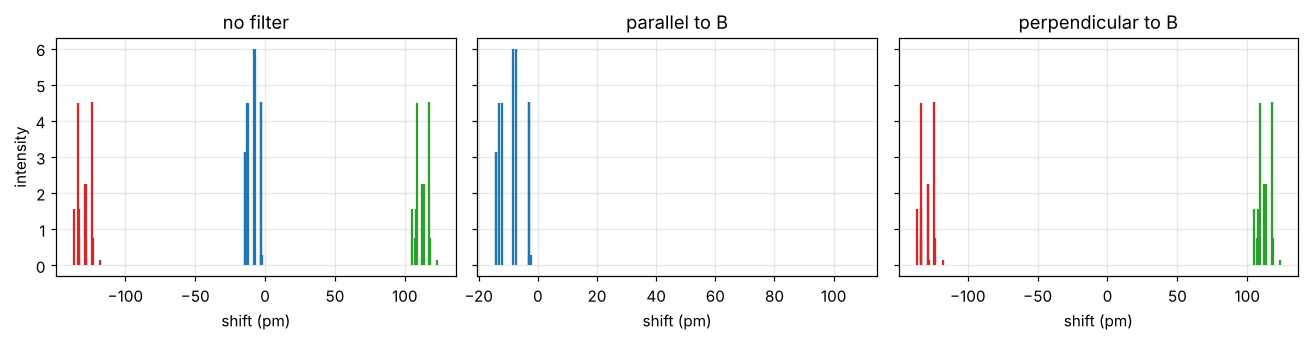

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
comps = balmer_components(6.0)
for ax, (name, m) in zip(axes, [('no filter', None), ('parallel to B', linear_polariser(0)), ('perpendicular to B', linear_polariser(90))]):
    d = observe(comps, 90.0, m)
    d = d[d.observed > 0.003*d.observed.max()]
    ax.vlines(d.shift_pm, 0, d.observed, color=d.polarisation.map({'pi':'tab:blue','sigma+':'tab:red','sigma-':'tab:green'}))
    ax.set_title(name); ax.set_xlabel('shift (pm)')
axes[0].set_ylabel('intensity')
plt.tight_layout(); plt.show()

## The fan diagram

![fan](../docs/figures/halpha_fan.png)

The sigma components approach the dashed normal-Zeeman lines and the pi components stay near the centre.

**Take-away.** The same machinery (diagonalise, apply the dipole operator, push through Jones matrices) works for a second atom with
a richer shell structure. Only the Hamiltonian and the radial factor changed.